# 09 &nbsp;Who should get the email at all?

**The question in dollars.** Notebook 08 found that uplift models couldn't reliably tell who responds more. But a ranking can be imperfect and still save money, for example by skipping customers predicted to be unmoved. So the real test is: **does any targeting policy make more profit than simply emailing everyone?**

**How a policy is valued.** Customers were assigned at random with a known 50/50 chance, so the profit of *any* rule for who gets the email can be estimated from the test itself. The customers whose actual group matches what the rule would have done stand in for everyone like them (inverse propensity weighting). Every customer is scored by a model trained without them, and every interval comes from a bootstrap that resamples all policies together, so comparisons between them are fair.

Profit uses the plan's assumptions: 35% margin and $0.02 per email, per 1,000 customers, compared with emailing nobody.

In [1]:
import numpy as np
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.readout import covariate_matrix
from exptoolkit.spec import load_spec
from exptoolkit.uplift import TLearner, XLearner, cross_fit_scores, evaluate_policies, policy_profit

style.use_style()
spec = load_spec("hillstrom_email.yaml")
margin, cost = spec.economics.gross_margin, spec.economics.cost_per_email
df = load_hillstrom()
d = df[df["arm"].isin(["control", "mens_email"])].reset_index(drop=True)
X = covariate_matrix(d, ["recency", "history", "mens", "womens", "newbie", "channel", "zip_code"])
t = (d["arm"] == "mens_email").astype(int).to_numpy()
y = d["spend"].to_numpy()

tau = {"X": cross_fit_scores(XLearner, X, y, t, seed=0),
       "T": cross_fit_scores(TLearner, X, y, t, seed=0)}
history = d["history"].to_numpy()

## 1. Six ways to decide who gets the email

- **Email everyone**: the decision from notebook 07.
- **Email nobody**: the baseline every profit is measured against.
- **X-learner / T-learner, profitable only**: email a customer only if their predicted lift covers the cost of the email.
- **X-learner, top half**: email the half with the highest predicted lift.
- **Past spend, top half**: email the half who spent most last year. No model needed.

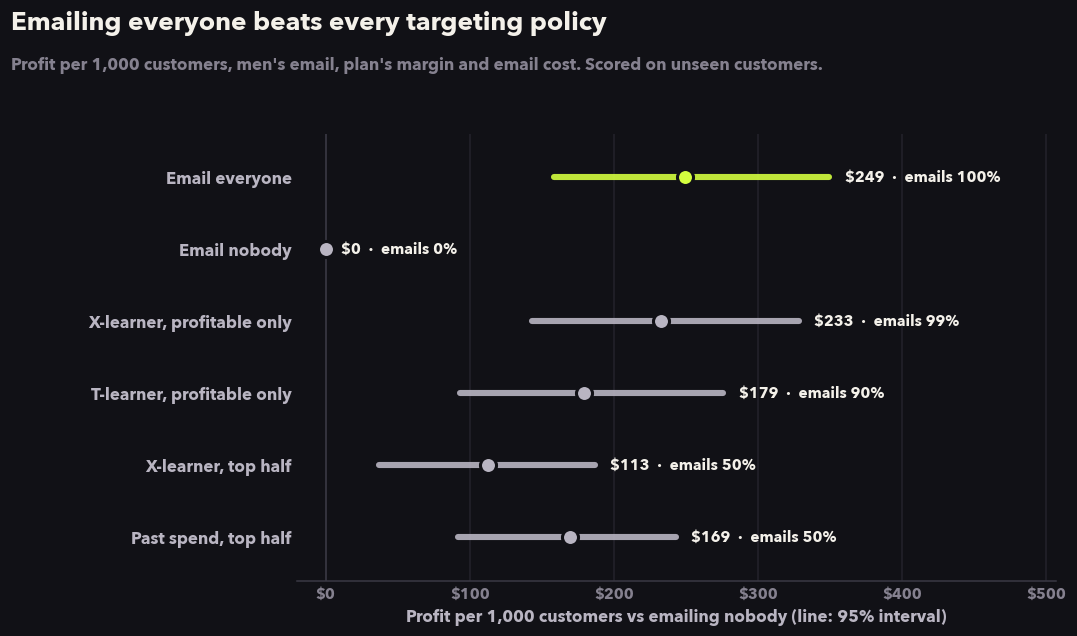

In [2]:
policies = {
    "Email everyone": np.ones(len(y), bool),
    "Email nobody": np.zeros(len(y), bool),
    "X-learner, profitable only": tau["X"] * margin > cost,
    "T-learner, profitable only": tau["T"] * margin > cost,
    "X-learner, top half": tau["X"] > np.median(tau["X"]),
    "Past spend, top half": history > np.median(history),
}
results = evaluate_policies(policies, y, t, margin, cost, n_boot=1000, seed=1)

fig, ax = plots.policy_plot(results, best="Email everyone")
style.headline(fig, "Emailing everyone beats every targeting policy",
               "Profit per 1,000 customers, men's email, plan's margin and email cost. Scored on unseen customers.")
style.save(fig, "policies")

In [3]:
def usd(v):
    return f"{'+' if v > 0 else '-' if v < 0 else ''}${abs(v):,.0f}"

shown = pd.DataFrame({
    "Customers emailed": results["share_sent"].map("{:.0%}".format),
    "Profit per 1,000": results["profit"].map(usd),
    "95% interval": [f"{usd(a)} to {usd(b)}" for a, b in zip(results["low"], results["high"])],
    "vs emailing everyone": [f"{usd(m)} ({usd(a)} to {usd(b)})" if k != "Email everyone" else ""
                             for k, m, a, b in zip(results.index, results["vs_reference"],
                                                   results["vs_low"], results["vs_high"])],
})
shown

,Customers emailed,"Profit per 1,000",95% interval,vs emailing everyone
policy,,,,
Email everyone,100%,+$249,+$158 to +$349,
Email nobody,0%,$0,$0 to $0,-$251 (-$349 to -$158)
"X-learner, profitable only",99%,+$233,+$143 to +$328,-$17 (-$37 to -$1)
"T-learner, profitable only",90%,+$179,+$93 to +$276,-$70 (-$116 to -$28)
"X-learner, top half",50%,+$113,+$37 to +$187,-$137 (-$200 to -$71)
"Past spend, top half",50%,+$169,+$92 to +$243,-$82 (-$149 to -$21)


Every targeting policy makes **less** money than emailing everyone, and for each one the gap's interval sits entirely below zero. The "profitable only" policies come closest because they still email most customers: the models predict a lift above the 5.7 cent break-even for nearly everyone. The policies that skip half the list give up the most, because the half they skip still responds.

## 2. Would targeting pay if emails cost more?

Targeting earns its keep when emails are expensive: then skipping weak responders saves real money. The plan's 2 cents is cheap. So the same policies are re-run for email costs up to 60 cents, which could stand for a costly channel such as direct mail, or a heavy allowance for unsubscribes.

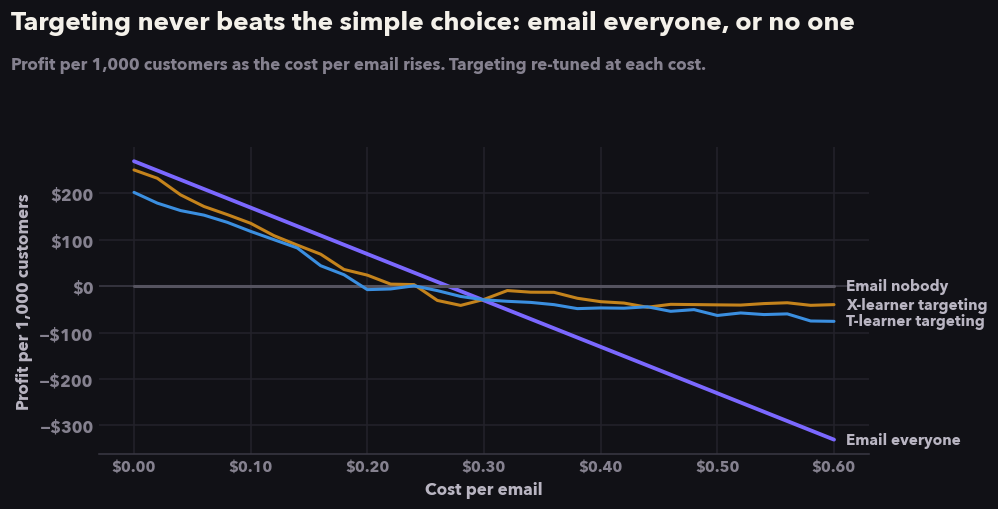

In [4]:
costs = np.round(np.arange(0.0, 0.601, 0.02), 2)
curves = {
    "Email everyone": [policy_profit(np.ones(len(y), bool), y, t, margin, c) for c in costs],
    "Email nobody": [0.0 for c in costs],
    "X-learner targeting": [policy_profit(tau["X"] * margin > c, y, t, margin, c) for c in costs],
    "T-learner targeting": [policy_profit(tau["T"] * margin > c, y, t, margin, c) for c in costs],
}
fig, ax = plots.cost_curve_plot(costs, curves)
style.headline(fig, "Targeting never beats the simple choice: email everyone, or no one",
               "Profit per 1,000 customers as the cost per email rises. Targeting re-tuned at each cost.")
style.save(fig, "cost_curve")

In [5]:
simple = np.maximum(curves["Email everyone"], 0.0)
targeted = np.maximum(curves["X-learner targeting"], curves["T-learner targeting"])
crossover = costs[np.argmax(np.array(curves["Email everyone"]) < 0)]
print(f"Email costs where a targeting model beats the better simple choice: "
      f"{int((targeted > simple + 1e-9).sum())} of {len(costs)}")
print(f"Emailing everyone stops paying at about ${crossover:.2f} per email")

Email costs where a targeting model beats the better simple choice: 0 of 31
Emailing everyone stops paying at about $0.28 per email


## What this tells us

- **Email everyone.** At the plan's assumptions it makes about **$250 profit per 1,000 customers**, more than any targeting policy, and the gap is larger than the noise for every alternative.
- **Don't build a targeting model for this email yet.** At no email cost from 0 to 60 cents did either model beat the better of the two simple choices. When the email pays, everyone should get it. When it doesn't, no one should. The model never finds a profitable middle.
- **Why targeting fails here.** The email lifts almost everyone well above break-even (notebook 08), and the data can't separate strong responders from weak ones. Targeting needs both: real differences, and enough signal to see them.

**When to revisit.** Targeting becomes worth testing again if (1) the email gets expensive, for example once unsubscribes are measured and priced in; (2) a test has many more buyers, since the signal grows with buyers, not customers; or (3) the outcome is purchases instead of revenue, which notebook 04 showed carries a cleaner signal. The general habit: before shipping a targeting model, price it against "everyone" and "no one" on held-out data. It is a cheap check that often saves building something that loses money.